#### Zweck: Skript als Proff of Concept für den Fluch der Dimensionalität am Beispiel der MNIST handgeschriebenen Ziffern
#### Autor: Willi Hahn

#### Versionsgeschichte
- 1.0 Willi Hahn 28.10.2026 Initial mit deepseek 

#### Prompt: 

Schreibe ein vollständiges Python-Skript zur Visualisierung des "Fluchs der Dimensionalität" am Beispiel des MNIST-Datensatzes. 

WICHTIGE ANFORDERUNGEN:

1. DATEN:
   - Lade den MNIST-Datensatz über sklearn.datasets.fetch_openml (mnist_784).
   - Nutze 1000 Samples, normalisiere die Pixelwerte auf 0-1 und forme sie in 28x28 Bilder um.
   - Falls der Download fehlschlägt, erstelle Zufallsdaten als Fallback.

2. DIMENSIONSREDUKTION (OHNE PCA!):
   - Verwende KEINE PCA, sondern eine einfache Mittelwertbildung (Average Pooling) über scipy.ndimage.zoom.
   - Reduziere die Bilder auf 32, 128 und 784 Dimensionen.
   - Fülle fehlende Dimensionen mit Nullen auf oder schneide ab, damit die Zielanzahl exakt erreicht wird.

3. ABSTANDSBERECHNUNG:
   - Berechne die paarweisen euklidischen Abstände mit sklearn.metrics.pairwise_distances.
   - Nutze nur die obere Dreiecksmatrix (ohne Diagonale), um Duplikate zu vermeiden.

4. ZWEI PLOTS (jeweils 3 Subplots nebeneinander für 32, 128, 784 Dimensionen):
   - PLOT 1 "Absolute Abstände": Histogramme der absoluten Abstände. Zeige den Mittelwert als rote gestrichelte Linie an. Titel: "Absolute Abstände werden GRÖSSER".
   - PLOT 2 "Relative Abstände": Normiere die Abstände auf den Mittelwert (rel_dist = |d| / mean(d)). Setze die X-Achse fest auf 0.5 bis 1.5. Zeige die relative Streuung (Standardabweichung der normierten Werte) als Text im Plot an. Titel: "Relative Abstände werden KLEINER (ähnlicher)".

5. KONSOLEN-OUTPUT:
   - Gib vor Plot 1 eine kurze Erklärung aus, dass die absoluten Abstände wachsen.
   - Gib vor Plot 2 eine ausführliche Zusammenfassung mit folgendem Inhalt aus:
     * Definition des relativen Abstands.
     * Formel: rel_dist = |d| / mean(d) mit Erklärung der Variablen.
     * Warum das wichtig ist: Bei 32 Dimensionen streuen die Werte stark (z.B. 0.66), bei 784 Dimensionen kaum (z.B. 0.98).
     * Fazit: Das ist der Fluch der Dimensionalität – Algorithmen können nicht mehr zwischen "ähnlich" und "unähnlich" unterscheiden.
   - Formatiere den Output mit Trennlinien (z.B. "="*70) für bessere Lesbarkeit.

6. STRUKTUR:
   - Nutze saubere Funktionen: load_data(), reduce_dimensions_average_pooling(), calculate_distances(), plot_absolute_distances(), plot_relative_distances().
   - Alles in einem einzigen, lauffähigen Skript mit if __name__ == "__main__": Block.
   - Kommentare auf Deutsch.

Lade MNIST-Daten...

TEIL 1: ABSOLUTE ABSTÄNDE
Berechne absolute Abstände mit Mittelwert-Reduktion...
Beobachtung: Der Berg (Mittelwert) wandert mit steigender Dimension nach rechts.
Die absoluten Abstände zwischen den Bildern werden größer.


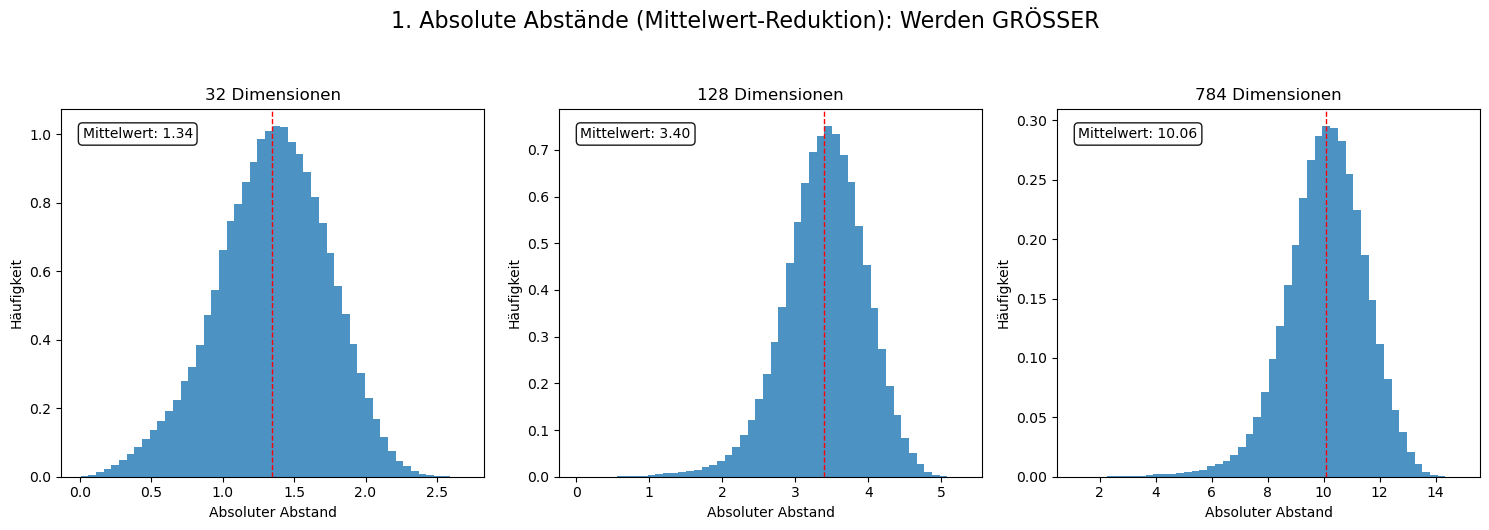


TEIL 2: RELATIVE ABSTÄNDE
Berechne relative Abstände mit Mittelwert-Reduktion...
----------------------------------------------------------------------
ZUSAMMENFASSUNG: RELATIVE ABSTÄNDE
----------------------------------------------------------------------
Was ist ein relativer Abstand?
Der relative Abstand normiert einen konkreten Abstand auf den Durchschnitt
aller Abstände. Dadurch wird er vergleichbar, unabhängig von der Skala.

FORMEL:
    rel_dist = |d| / mean(d)

Wobei:
    |d|     = absoluter euklidischer Abstand zwischen zwei Bildern
    mean(d) = Mittelwert aller paarweisen Abstände im Datensatz

WARUM IST DAS WICHTIG?
- Bei wenigen Dimensionen (z.B. 32) streuen die relativen Abstände stark.
  Der nächste Nachbar liegt z.B. bei 0.66 (66% des Durchschnitts).
  -> Man kann 'nah' und 'fern' gut unterscheiden.

- Bei vielen Dimensionen (z.B. 784) streuen die relativen Abstände kaum.
  Der nächste Nachbar liegt z.B. bei 0.98 (98% des Durchschnitts).
  -> Alle Punkte scheinen glei

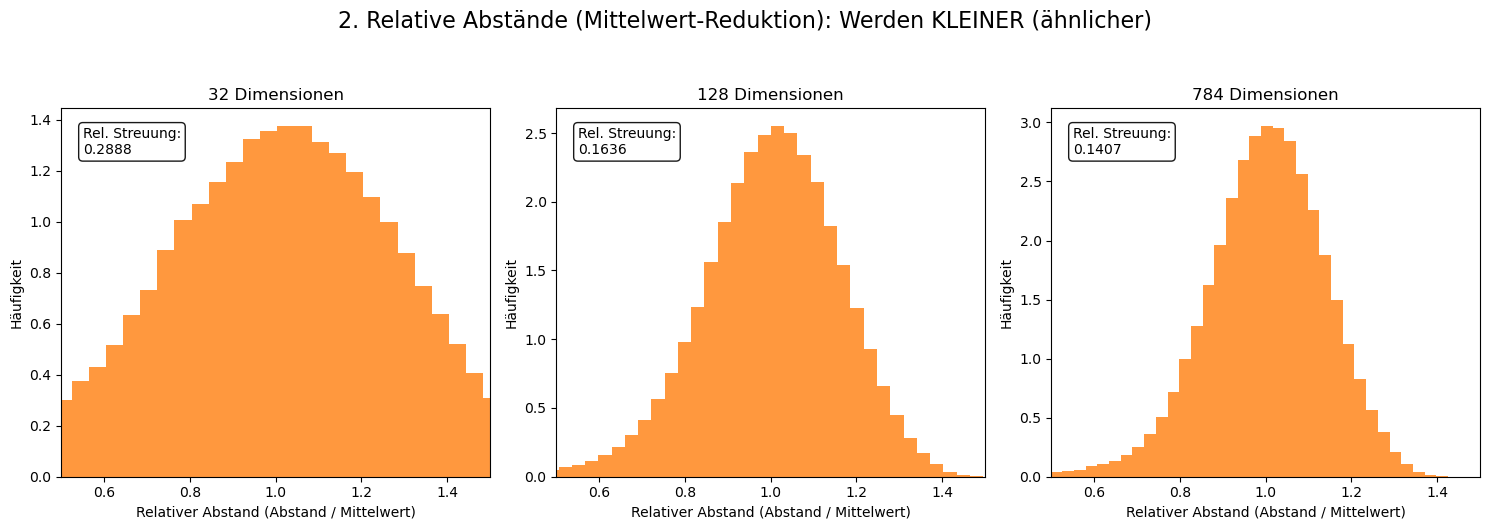

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.metrics import pairwise_distances
from scipy.ndimage import zoom

def load_data(n_samples=1000):
    """Lädt MNIST-Daten oder erstellt Zufallsdaten."""
    print("Lade MNIST-Daten...")
    try:
        mnist = fetch_openml('mnist_784', version=1, parser='auto')
        X = mnist.data.values[:n_samples] / 255.0
        X = X.reshape(-1, 28, 28)
    except Exception as e:
        print(f"Fehler beim Laden: {e}. Erstelle simulierte Daten.")
        np.random.seed(42)
        X = np.random.rand(n_samples, 28, 28)
    return X

def reduce_dimensions_average_pooling(X, target_dims):
    """Reduziert die Dimensionen durch einfache Mittelwertbildung."""
    n_samples, h, w = X.shape
    original_dims = h * w
    
    if target_dims >= original_dims:
        return X.reshape(n_samples, -1)
    
    new_side = int(np.sqrt(target_dims))
    zoom_factor = new_side / h
    
    X_reduced = np.array([zoom(img, zoom_factor, order=1) for img in X])
    X_flat = X_reduced.reshape(n_samples, -1)
    
    if X_flat.shape[1] < target_dims:
        padding = np.zeros((n_samples, target_dims - X_flat.shape[1]))
        X_flat = np.hstack([X_flat, padding])
    elif X_flat.shape[1] > target_dims:
        X_flat = X_flat[:, :target_dims]
        
    return X_flat

def calculate_distances(X_reduced):
    """Berechnet paarweise euklidische Abstände."""
    dists = pairwise_distances(X_reduced, metric='euclidean')
    triu_indices = np.triu_indices_from(dists, k=1)
    return dists[triu_indices]

def plot_absolute_distances(dimensions, data):
    """Plot 1: Absolute Abstände (Der Berg wandert nach rechts)."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle("1. Absolute Abstände (Mittelwert-Reduktion): Werden GRÖSSER", fontsize=16, y=1.05)
    
    for i, dim in enumerate(dimensions):
        X_reduced = reduce_dimensions_average_pooling(data, dim)
        dists = calculate_distances(X_reduced)
        mean_dist = np.mean(dists)
        
        ax = axes[i]
        ax.hist(dists, bins=50, color='#1f77b4', alpha=0.8, density=True)
        ax.set_title(f"{dim} Dimensionen")
        ax.set_xlabel("Absoluter Abstand")
        ax.set_ylabel("Häufigkeit")
        
        ax.axvline(mean_dist, color='red', linestyle='dashed', linewidth=1)
        ax.text(0.05, 0.95, f"Mittelwert: {mean_dist:.2f}", 
                transform=ax.transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))

    plt.tight_layout()
    plt.show()

def plot_relative_distances(dimensions, data):
    """Plot 2: Relative Abstände (Der Berg wird schmaler)."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle("2. Relative Abstände (Mittelwert-Reduktion): Werden KLEINER (ähnlicher)", fontsize=16, y=1.05)
    
    for i, dim in enumerate(dimensions):
        X_reduced = reduce_dimensions_average_pooling(data, dim)
        dists = calculate_distances(X_reduced)
        
        # Normierung auf 1.0
        normalized_dists = dists / np.mean(dists)
        rel_spread = np.std(normalized_dists)
        
        ax = axes[i]
        ax.hist(normalized_dists, bins=50, color='#ff7f0e', alpha=0.8, density=True)
        ax.set_title(f"{dim} Dimensionen")
        ax.set_xlabel("Relativer Abstand (Abstand / Mittelwert)")
        ax.set_ylabel("Häufigkeit")
        
        ax.set_xlim(0.5, 1.5) 
        
        ax.text(0.05, 0.95, f"Rel. Streuung:\n{rel_spread:.4f}", 
                transform=ax.transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    # 1. Daten laden
    X = load_data(n_samples=1000)
    
    # 2. Dimensionen definieren
    dimensions_to_test = [32, 128, 784]
    
    print("\n" + "="*70)
    print("TEIL 1: ABSOLUTE ABSTÄNDE")
    print("="*70)
    print("Berechne absolute Abstände mit Mittelwert-Reduktion...")
    print("Beobachtung: Der Berg (Mittelwert) wandert mit steigender Dimension nach rechts.")
    print("Die absoluten Abstände zwischen den Bildern werden größer.")
    plot_absolute_distances(dimensions_to_test, X)
    
    print("\n" + "="*70)
    print("TEIL 2: RELATIVE ABSTÄNDE")
    print("="*70)
    print("Berechne relative Abstände mit Mittelwert-Reduktion...")
    print("-" * 70)
    print("ZUSAMMENFASSUNG: RELATIVE ABSTÄNDE")
    print("-" * 70)
    print("Was ist ein relativer Abstand?")
    print("Der relative Abstand normiert einen konkreten Abstand auf den Durchschnitt")
    print("aller Abstände. Dadurch wird er vergleichbar, unabhängig von der Skala.")
    print()
    print("FORMEL:")
    print("    rel_dist = |d| / mean(d)")
    print()
    print("Wobei:")
    print("    |d|     = absoluter euklidischer Abstand zwischen zwei Bildern")
    print("    mean(d) = Mittelwert aller paarweisen Abstände im Datensatz")
    print()
    print("WARUM IST DAS WICHTIG?")
    print("- Bei wenigen Dimensionen (z.B. 32) streuen die relativen Abstände stark.")
    print("  Der nächste Nachbar liegt z.B. bei 0.66 (66% des Durchschnitts).")
    print("  -> Man kann 'nah' und 'fern' gut unterscheiden.")
    print()
    print("- Bei vielen Dimensionen (z.B. 784) streuen die relativen Abstände kaum.")
    print("  Der nächste Nachbar liegt z.B. bei 0.98 (98% des Durchschnitts).")
    print("  -> Alle Punkte scheinen gleich weit entfernt zu sein.")
    print()
    print("DAS IST DER FLUCH DER DIMENSIONALITÄT:")
    print("Die absoluten Abstände wachsen (der Berg wandert nach rechts),")
    print("aber die relativen Abstände werden immer ähnlicher (der Berg wird schmaler).")
    print("Algorithmen können dann nicht mehr zwischen 'ähnlich' und 'unähnlich' unterscheiden.")
    print("-" * 70)
    
    plot_relative_distances(dimensions_to_test, X)